In [1]:
RANDOM_STATE = 42
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "data/raw").exists() else Path.cwd().parent
assert (ROOT / "data/raw/application_record.csv").exists(), "Extraia o pacote completo antes de executar."
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from common import load, prepare, FEATURES, preprocessing
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
OUT = ROOT / "data/processed"
OUT.mkdir(parents=True, exist_ok=True)
RESULTS = ROOT / "docs/resultados"
RESULTS.mkdir(parents=True, exist_ok=True)

# 01 — Análise exploratória
Objetivo: entender cadastro, histórico mensal e população observável, sem modificar os dados brutos.

In [2]:
a,c=load(ROOT)
d,t,conflicts=prepare(a,c)
display(pd.DataFrame({'linhas':[len(a),len(c)],'colunas':[a.shape[1],c.shape[1]],'ids':[a.ID.nunique(),c.ID.nunique()]},index=['cadastro','credito']))
display(a.isna().sum().to_frame('nulos'))
display(a.describe().T)
print('IDs conflitantes:',len(conflicts),'Clientes na ABT:',len(d),'Perfis:',d.PERFIL_ID.nunique())

,linhas,colunas,ids
cadastro,438557,18,438510
credito,1048575,3,45985


,nulos
ID,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0
NAME_FAMILY_STATUS,0
NAME_HOUSING_TYPE,0


,count,mean,std,min,25%,50%,75%,max
ID,438557.0,6.022176e+06,571637.023257,5008804.0,5609375.0,6047745.0,6456971.0,7999952.0
CNT_CHILDREN,438557.0,4.273903e-01,0.724882,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,438557.0,1.875243e+05,110086.853066,26100.0,121500.0,160780.5,225000.0,6750000.0
DAYS_BIRTH,438557.0,-1.599790e+04,4185.030007,-25201.0,-19483.0,-15630.0,-12514.0,-7489.0
DAYS_EMPLOYED,438557.0,6.056368e+04,138767.799647,-17531.0,-3103.0,-1467.0,-371.0,365243.0
FLAG_MOBIL,438557.0,1.000000e+00,0.000000,1.0,1.0,1.0,1.0,1.0
FLAG_WORK_PHONE,438557.0,2.061328e-01,0.404527,0.0,0.0,0.0,0.0,1.0
FLAG_PHONE,438557.0,2.877710e-01,0.452724,0.0,0.0,0.0,1.0,1.0
FLAG_EMAIL,438557.0,1.082071e-01,0.310642,0.0,0.0,0.0,0.0,1.0
CNT_FAM_MEMBERS,438557.0,2.194465e+00,0.897207,1.0,2.0,2.0,3.0,20.0


IDs conflitantes: 47 Clientes na ABT: 36457 Perfis: 9728


## Distribuições e outliers

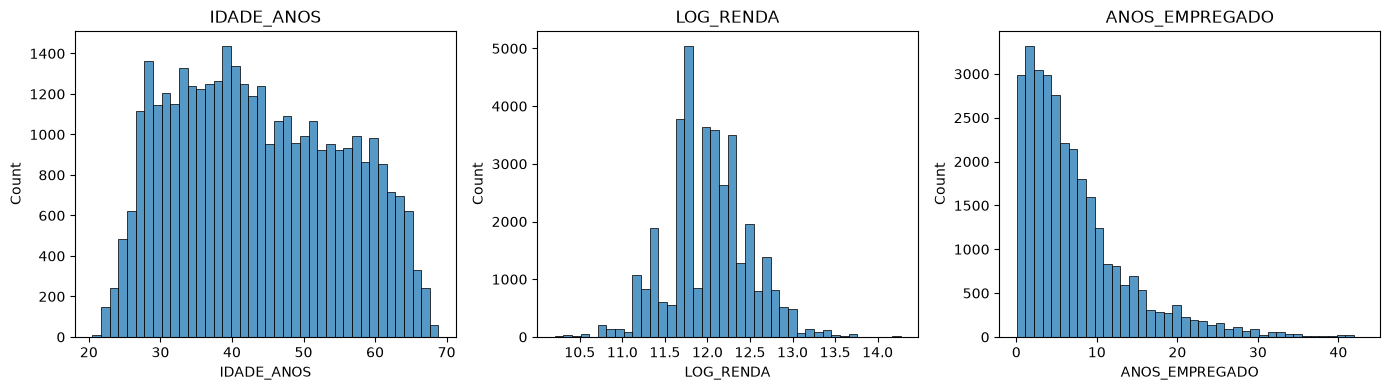

In [3]:
fig,ax=plt.subplots(1,3,figsize=(14,4))
for axis,col in zip(ax,['IDADE_ANOS','LOG_RENDA','ANOS_EMPREGADO']):
    sns.histplot(d[col],bins=40,ax=axis); axis.set_title(col)
plt.tight_layout();plt.show()

A transformação logarítmica permite visualizar a renda sem que os maiores valores dominem o eixo. O tempo de emprego desconhecido permanece ausente, em vez de ser confundido com zero. Valores extremos válidos são preservados: estar fora do IQR não demonstra erro de cadastro. A unidade monetária e a periodicidade da renda não foram verificadas; não rotular como reais.

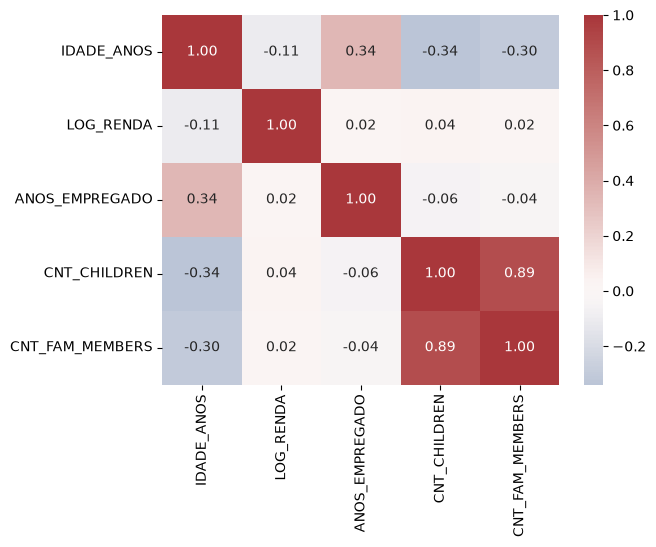

In [4]:
num=d[['IDADE_ANOS','LOG_RENDA','ANOS_EMPREGADO','CNT_CHILDREN','CNT_FAM_MEMBERS']]
sns.heatmap(num.corr(),annot=True,fmt='.2f',cmap='vlag',center=0);plt.show()

Nesta execução, filhos e tamanho familiar apresentam correlação de 0,889; idade e tempo de emprego, 0,341; idade e filhos, -0,339; idade e membros da família, -0,304. Renda logarítmica apresenta relações lineares fracas com os demais atributos. Essas associações justificam cautela com redundância e coeficientes; não demonstram causalidade nem discriminação do alvo.

,positivos,taxa
30+ dias,4291,0.117700
90+ dias,302,0.008284


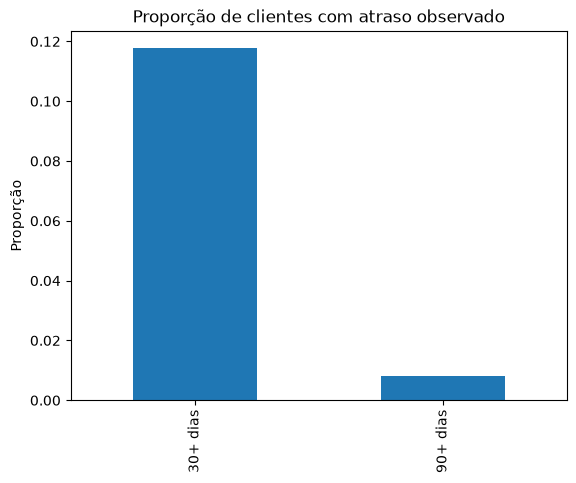

In [5]:
res=pd.DataFrame({'positivos':[d.TARGET_30.sum(),d.TARGET_90.sum()], 'taxa':[d.TARGET_30.mean(),d.TARGET_90.mean()]},index=['30+ dias','90+ dias'])
display(res)
res.taxa.plot.bar(title='Proporção de clientes com atraso observado');plt.ylabel('Proporção');plt.show()

O critério 90+ é subconjunto do 30+ e oferece menos exemplos positivos. O alvo principal será 30+ por representar um sinal mais abrangente de atraso relevante; isso é uma hipótese operacional, não uma definição universal de inadimplência. A escolha não deve ser feita para melhorar artificialmente a acurácia.

,count,mean
MESES_HISTORICO,,
"(0, 6]",5944,0.040040
"(6, 12]",7094,0.105441
"(12, 24]",10266,0.130820
"(24, 36]",6502,0.133497
"(36, 61]",6651,0.164487


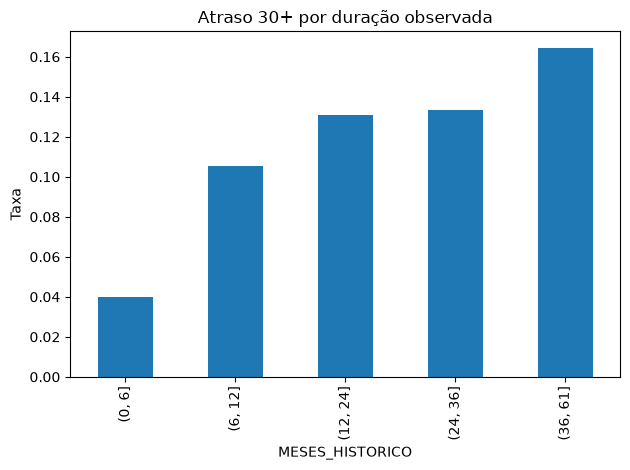

In [6]:
expos=d.groupby(pd.cut(d.MESES_HISTORICO,[0,6,12,24,36,61]),observed=False).TARGET.agg(['count','mean'])
display(expos)
expos['mean'].plot.bar(title='Atraso 30+ por duração observada');plt.ylabel('Taxa');plt.tight_layout();plt.show()

A comparação usa diferentes oportunidades de observar atraso. Históricos mais longos podem acumular mais eventos; por isso duração e datas do histórico serão excluídas dos preditores. O cadastro não possui data de fotografia confirmada, impossibilitando uma validação prospectiva rigorosa. O modelo será avaliado como classificação de histórico observado.

## Síntese
Há seleção por disponibilidade de histórico, classe positiva minoritária, dados de ocupação ausentes e perfis repetidos sob IDs diferentes. A próxima etapa resolve integridade e define uma lista explícita de atributos; a modelagem separa perfis entre conjuntos.